### Langkah 5: Evaluasi Mendalam & Analisis Probabilitas (Balanced Random Forest)

Pada langkah ini, kita membedah performa model terpilih kita yaitu Balanced Random Forest:
1. Confusion Matrix & Cost-Matrix Analysis: Melihat berapa nasabah macet yang berhasil ditangkal.
2. Classification Report: Mengukur Precision, Recall, dan F1-Score per kelas nasabah.
3. Feature Importance (Explainable AI): Mencari tahu faktor apa yang paling menentukan seseorang layak atau tidak (misal: nominal pinjaman rupiah, status rekening giro, umur).
4. Simulasi Skor Kelayakan (0 - 100%): Menguji bagaimana model memberikan keputusan persetujuan kredit dengan threshold bank.

### 1. Import Library & Load Data Train-Test

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

possible_paths = ["train_test_data.npz", os.path.join("data", "train_test_data.npz"), os.path.join("..", "data", "train_test_data.npz")]
DATA_PATH = next((p for p in possible_paths if os.path.exists(p)), None)
data = np.load(DATA_PATH, allow_pickle=True)
X_train, X_test = data["X_train"], data["X_test"]
y_train, y_test = data["y_train"], data["y_test"]
feature_names = data["feature_names"]
print(f"✓ Data berhasil dimuat: {DATA_PATH}")
print(f"✓ X_train: {X_train.shape}, X_test: {X_test.shape}")

✓ Data berhasil dimuat: data\train_test_data.npz
✓ X_train: (800, 48), X_test: (200, 48)


### 2. Melatih Model Balanced Random Forest

In [2]:
model = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, y_prob)
print("✓ Model Balanced Random Forest selesai dilatih!")
print(f"✓ Skor ROC-AUC pada data uji: {auc_score*100:.2f}%")

✓ Model Balanced Random Forest selesai dilatih!
✓ Skor ROC-AUC pada data uji: 77.33%


### 3. Evaluasi Confusion Matrix (Deteksi Risiko Macet)

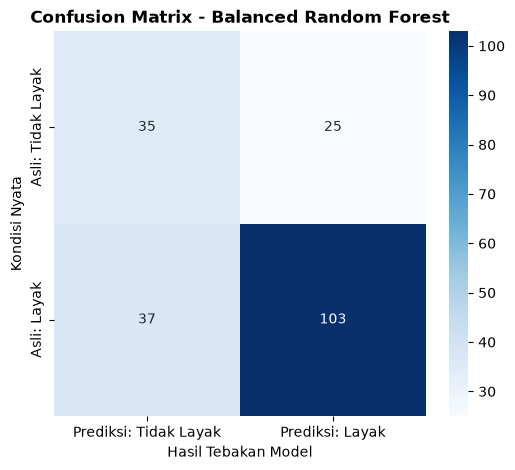

Confusion Matrix:
[[ 35  25]
 [ 37 103]]

✓ Nasabah Macet Terdeteksi (True Negative) : 35 dari 60 orang (58.3%)
✓ Nasabah Baik Lolos     (True Positive) : 103 dari 140 orang (73.6%)
⚠️ Nasabah Macet Lolos   (False Positive): 25 orang


In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prediksi: Tidak Layak", "Prediksi: Layak"],
            yticklabels=["Asli: Tidak Layak", "Asli: Layak"])
plt.title("Confusion Matrix - Balanced Random Forest", fontsize=12, fontweight="bold")
plt.ylabel("Kondisi Nyata")
plt.xlabel("Hasil Tebakan Model")
plt.show()

print(f"Confusion Matrix:\n{cm}\n")
print(f"✓ Nasabah Macet Terdeteksi (True Negative) : {cm[0,0]} dari 60 orang ({cm[0,0]/60*100:.1f}%)")
print(f"✓ Nasabah Baik Lolos     (True Positive) : {cm[1,1]} dari 140 orang ({cm[1,1]/140*100:.1f}%)")
print(f"⚠️ Nasabah Macet Lolos   (False Positive): {cm[0,1]} orang")

### 4. Classification Report

In [4]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Tidak Layak (Bad)", "Layak (Good)"]))
report_dict = classification_report(y_test, y_pred, target_names=["Tidak Layak (Bad)", "Layak (Good)"], output_dict=True)
pd.DataFrame(report_dict).transpose().round(2)

Classification Report:
                   precision    recall  f1-score   support

Tidak Layak (Bad)       0.49      0.58      0.53        60
     Layak (Good)       0.80      0.74      0.77       140

         accuracy                           0.69       200
        macro avg       0.65      0.66      0.65       200
     weighted avg       0.71      0.69      0.70       200



,precision,recall,f1-score,support
Tidak Layak (Bad),0.49,0.58,0.53,60.00
Layak (Good),0.80,0.74,0.77,140.00
accuracy,0.69,0.69,0.69,0.69
macro avg,0.65,0.66,0.65,200.00
weighted avg,0.71,0.69,0.70,200.00


### 5. Feature Importance: Faktor Apa yang Paling Mempengaruhi Kelayakan?

C:\Users\daffaakmal\AppData\Local\Temp\ipykernel_12984\1385937787.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis")


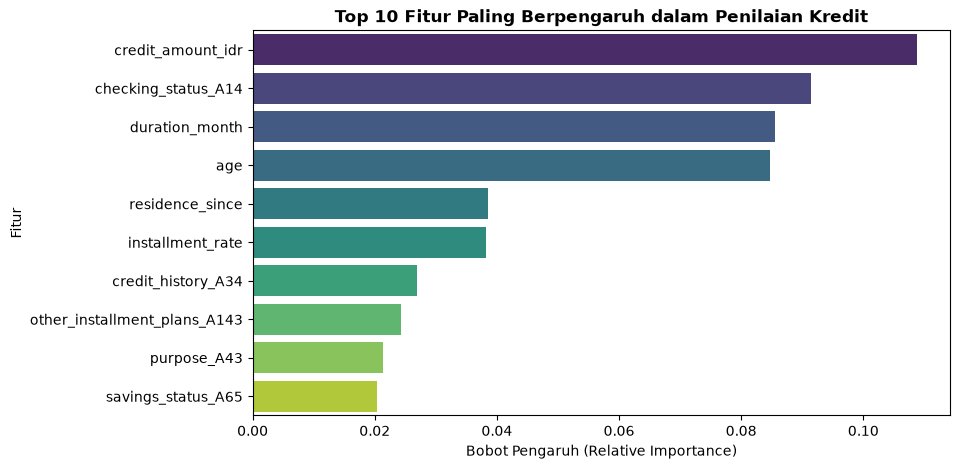

,Fitur,Tingkat Kepentingan
0,credit_amount_idr,0.1088
1,checking_status_A14,0.0914
2,duration_month,0.0855
3,age,0.0848
4,residence_since,0.0386
5,installment_rate,0.0383
6,credit_history_A34,0.0269
7,other_installment_plans_A143,0.0243
8,purpose_A43,0.0213
9,savings_status_A65,0.0204


In [5]:
feat_imp = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis")
plt.title("Top 10 Fitur Paling Berpengaruh dalam Penilaian Kredit", fontsize=12, fontweight="bold")
plt.xlabel("Bobot Pengaruh (Relative Importance)")
plt.ylabel("Fitur")
plt.show()

pd.DataFrame({"Fitur": feat_imp.index, "Tingkat Kepentingan": feat_imp.values.round(4)})

### 6. Simulasi Skor Kelayakan Kredit (0 - 100%) & Keputusan Bank

In [6]:
sample_df = pd.DataFrame({
    "Nasabah ID": [f"Nasabah {i+1}" for i in range(10)],
    "Status Asli": ["Layak (Good)" if v == 1 else "Tidak Layak (Bad)" for v in y_test[:10]],
    "Skor Kelayakan (%)": np.round(y_prob[:10] * 100, 1),
    "Keputusan (Threshold 50%)": ["DISETUJUI" if p >= 0.5 else "DITOLAK" for p in y_prob[:10]]
})
sample_df

,Nasabah ID,Status Asli,Skor Kelayakan (%),Keputusan (Threshold 50%)
0,Nasabah 1,Layak (Good),64.0,DISETUJUI
1,Nasabah 2,Layak (Good),25.0,DITOLAK
2,Nasabah 3,Layak (Good),57.0,DISETUJUI
3,Nasabah 4,Layak (Good),82.0,DISETUJUI
4,Nasabah 5,Tidak Layak (Bad),50.0,DISETUJUI
5,Nasabah 6,Layak (Good),53.0,DISETUJUI
6,Nasabah 7,Layak (Good),73.0,DISETUJUI
7,Nasabah 8,Tidak Layak (Bad),50.0,DISETUJUI
8,Nasabah 9,Tidak Layak (Bad),45.0,DITOLAK
9,Nasabah 10,Layak (Good),62.0,DISETUJUI
